# Predicting Card Mana Value in the MTG Star Trek Set
## 1. Project Setup and Data Ingestion
This notebook executes the data pipeline and Random Forest classification model outlined in the PACE Strategy Document. The goal is to predict a card's balanced mana cost based on its base stats and unstructured ability text using Natural Language Processing (NLP).

In [16]:
import pandas as pd
import numpy as np
import requests
import time

headers = {'User-Agent': 'MTG_Data_Project/1.0'}

# Search for the main set (trk) AND the supplementary/Commander set (trkc)
# Scryfall groups by unique card name by default, preventing duplicate alternate arts
url = "https://api.scryfall.com/cards/search?q=s:trk,trc&unique=prints"

all_cards = []
has_more = True

print("Fetching data from Scryfall...")

while has_more:
    response = requests.get(url, headers=headers)
    
    if response.status_code == 200:
        data = response.json()
        all_cards.extend(data['data']) # Add this page's cards to our master list
        
        has_more = data.get('has_more', False) # Check if there is another page
        if has_more:
            url = data['next_page'] # Overwrite the URL with the next page link
            time.sleep(0.1) # Best practice: pause 100ms between requests
    else:
        print(f"Error {response.status_code}: {response.json().get('details', 'Failed')}")
        break

print(f"Successfully downloaded {len(all_cards)} unique cards.")

Fetching data from Scryfall...
Successfully downloaded 1142 unique cards.


## 2. Data Loading & Initial Exploration
With the raw JSON data downloaded, the next step is to load it into a structured Pandas DataFrame. This allows inspection of the columns provided by the Scryfall API and identify which features (like mana cost, power, toughness, and oracle text) needed to isolate for the Random Forest model.

In [2]:
# Convert the list of JSON card dictionaries into a Pandas DataFrame
df = pd.DataFrame(all_cards)

# Display the datatypes
print(f"Dataframe information: {df.info(verbose=True, max_cols=None)}")

# Display the first 5 rows to inspect the data structure
pd.set_option('display.max_columns', None)
df.head()


<class 'pandas.DataFrame'>
RangeIndex: 1142 entries, 0 to 1141
Data columns (total 73 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   object             1142 non-null   str    
 1   id                 1142 non-null   str    
 2   oracle_id          1142 non-null   str    
 3   multiverse_ids     1142 non-null   object 
 4   resource_id        1049 non-null   str    
 5   mtgo_id            1004 non-null   float64
 6   tcgplayer_id       1139 non-null   float64
 7   cardmarket_id      650 non-null    float64
 8   name               1142 non-null   str    
 9   lang               1142 non-null   str    
 10  released_at        1142 non-null   str    
 11  uri                1142 non-null   str    
 12  scryfall_uri       1142 non-null   str    
 13  layout             1142 non-null   str    
 14  highres_image      1142 non-null   bool   
 15  image_status       1142 non-null   str    
 16  image_updated_at   1142 non-null   

,object,id,oracle_id,multiverse_ids,resource_id,mtgo_id,tcgplayer_id,cardmarket_id,name,lang,released_at,uri,scryfall_uri,layout,highres_image,image_status,image_updated_at,image_uris,mana_cost,cmc,type_line,oracle_text,colors,color_identity,keywords,legalities,games,reserved,game_changer,foil,nonfoil,finishes,oversized,promo,reprint,variation,set_id,set,set_name,set_type,set_uri,set_search_uri,scryfall_set_uri,rulings_uri,prints_search_uri,collector_number,digital,rarity,flavor_text,card_back_id,artist,artist_ids,illustration_id,border_color,frame,full_art,textless,booster,story_spotlight,promo_types,edhrec_rank,prices,related_uris,purchase_uris,penny_rank,power,toughness,all_parts,produced_mana,frame_effects,security_stamp,preview,flavor_name
0,card,02080f42-863a-471b-992b-67e35ef1b7b7,9356aee1-3d2b-4d17-8863-663e1ddf56f3,[],5C4FB9C107C8D8B2D4297751D95B760C1E36C6961FA9A1...,158142.0,728620.0,917666.0,"70,000 Light-Years from Home",en,2026-11-13,https://api.scryfall.com/cards/02080f42-863a-4...,https://scryfall.com/card/trk/1/70000-light-ye...,normal,True,highres_scan,2026-08-06T08:43:00Z,{'small': 'https://cards.scryfall.io/small/fro...,{1}{W},2.0,Sorcery,Exile target creature or Spacecraft. Its contr...,[W],[W],[],"{'standard': 'legal', 'future': 'legal', 'hist...","[paper, mtgo, arena]",False,False,True,True,"[nonfoil, foil]",False,False,False,False,b47039dc-da5a-448c-8feb-e77d458108a6,trk,Star Trek,expansion,https://api.scryfall.com/sets/b47039dc-da5a-44...,https://api.scryfall.com/cards/search?order=se...,https://scryfall.com/sets/trk?utm_source=api,https://api.scryfall.com/cards/02080f42-863a-4...,https://api.scryfall.com/cards/search?order=re...,1,False,uncommon,"""If these sensors are working . . . we're on t...",0aeebaf5-8c7d-4636-9e82-8c27447861f7,Ariel Orea,[acaba9f2-ef15-499c-9660-bf91cab2dbd6],3db3beee-6070-4345-a0b4-c27605a84a01,black,2015,False,False,False,False,[universesbeyond],26255.0,"{'usd': '0.26', 'usd_foil': '0.24', 'usd_etche...",{'tcgplayer_infinite_articles': 'https://partn...,{'tcgplayer': 'https://partner.tcgplayer.com/c...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,card,847b4081-25c9-4a9a-a2f3-d5fdadbfe81b,f9db72dc-9a5b-48a4-a86e-7464d9a2166a,[],6E42748D052EB8220B605524E2960C0F173EB9C3DEB012...,157116.0,726372.0,919573.0,Abrade,en,2026-11-13,https://api.scryfall.com/cards/847b4081-25c9-4...,https://scryfall.com/card/trc/449/abrade?utm_s...,normal,True,highres_scan,2026-10-27T14:38:14Z,{'small': 'https://cards.scryfall.io/small/fro...,{1}{R},2.0,Instant,Choose one —\n• Abrade deals 3 damage to targe...,[R],[R],[],"{'standard': 'legal', 'future': 'legal', 'hist...","[paper, mtgo]",False,False,True,True,"[nonfoil, foil]",False,False,True,False,a38c10be-90b1-4bb9-bd74-46784a751ac3,trc,Star Trek Commander,commander,https://api.scryfall.com/sets/a38c10be-90b1-4b...,https://api.scryfall.com/cards/search?order=se...,https://scryfall.com/sets/trc?utm_source=api,https://api.scryfall.com/cards/847b4081-25c9-4...,https://api.scryfall.com/cards/search?order=re...,449,False,uncommon,Quantum torpedoes channel a matter/antimatter ...,0aeebaf5-8c7d-4636-9e82-8c27447861f7,Bartek Fedyczak,[70b1ba71-4ee1-4087-8a9e-ea919f20ebff],0d2f7b6c-bf79-46e7-a547-368cdc28f225,black,2015,False,False,False,False,"[surgefoil, universesbeyond]",144.0,"{'usd': '0.32', 'usd_foil': None, 'usd_etched'...",{'tcgplayer_infinite_articles': 'https://partn...,{'tcgplayer': 'https://partner.tcgplayer.com/c...,242.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,card,660ec8bc-dc03-4b42-84f3-091c19e2a853,8802b7f0-1ed1-4872-9939-182afb8441ca,[],6E520F7756A51403038DA83894FD65EEEA177FB22E9D37...,158414.0,726700.0,919806.0,Academy Instructor,en,2026-11-13,https://api.scryfall.com/cards/660ec8bc-dc03-4...,https://scryfall.com/card/trk/137/academy-inst...,normal,True,highres_scan,2026-10-28T11:46:45Z,{'small': 'https://cards.scryfall.io/small/fro...,{2}{R},3.0,Creature — Bolian Officer,This creature gets +1/+0 for each Officer toke...,[R],[R],[],"{'standard': 'legal',

## 3. Feature Selection
The Scryfall API returns 72 columns, but our Random Forest model requires a specific subset to evaluate game balance. Isolating the mechanical identity (`oracle_id`), naming attributes (`name`, `flavor_name`), base stats (`power`, `toughness`), casting properties (`mana_cost`, `cmc`, `colors`), ability text (`oracle_text`), and set context (`type_line`, `rarity`, `reprint`, `legalities`).

In [3]:
# Define the target columns for the predictive model and EDA
columns_to_keep = [
    'oracle_id', 'name', 'flavor_name', 'mana_cost', 'colors', 
    'type_line', 'cmc', 'oracle_text', 'power', 'toughness', 
    'rarity', 'reprint', 'legalities', 'keywords'
]

# Create the focused dataframe
df_model = df[columns_to_keep].copy()

# Display the shape and first few rows to verify
print(f"Focused dataframe shape: {df_model.shape}")
df_model.head()

Focused dataframe shape: (1142, 14)


,oracle_id,name,flavor_name,mana_cost,colors,type_line,cmc,oracle_text,power,toughness,rarity,reprint,legalities,keywords
0,9356aee1-3d2b-4d17-8863-663e1ddf56f3,"70,000 Light-Years from Home",NaN,{1}{W},[W],Sorcery,2.0,Exile target creature or Spacecraft. Its contr...,NaN,NaN,uncommon,False,"{'standard': 'legal', 'future': 'legal', 'hist...",[]
1,f9db72dc-9a5b-48a4-a86e-7464d9a2166a,Abrade,NaN,{1}{R},[R],Instant,2.0,Choose one —\n• Abrade deals 3 damage to targe...,NaN,NaN,uncommon,True,"{'standard': 'legal', 'future': 'legal', 'hist...",[]
2,8802b7f0-1ed1-4872-9939-182afb8441ca,Academy Instructor,NaN,{2}{R},[R],Creature — Bolian Officer,3.0,This creature gets +1/+0 for each Officer toke...,0,3,uncommon,False,"{'standard': 'legal', 'future': 'legal', 'hist...",[]
3,a3da7d5b-2c2b-45fe-b9c5-413b8c8fc0a2,Academy Ruins,NaN,,[],Legendary Land,0.0,"{T}: Add {C}.\n{1}{U}, {T}: Put target artifac...",NaN,NaN,rare,True,"{'standard': 'not_legal', 'future': 'not_legal...",[]
4,a3da7d5b-2c2b-45fe-b9c5-413b8c8fc0a2,Academy Ruins,NaN,,[],Legendary Land,0.0,"{T}: Add {C}.\n{1}{U}, {T}: Put target artifac...",NaN,NaN,rare,True,"{'standard': 'not_legal', 'future': 'not_legal...",[]


## 4. Deduplication and Legalities Filter
Because the API query pulled all physical prints to capture the Star Trek flavor treatments and Commander cards, the dataset contains mechanically identical alternate arts. To prevent the Random Forest from over-indexing on cards with multiple printings (like Bristly Bill / Leonard McCoy), dropping duplicate rows based on their underlying `oracle_id`.

In [4]:
# Drop mechanically identical cards to prevent model skew, keeping the first occurrence
df_unique = df_model.drop_duplicates(subset=['oracle_id']).copy()

# Display the shape after removing alternate arts
print(f"Dataframe shape after deduplication: {df_unique.shape}")

# Verify how many unique flavor-named cards remain in the training set
flavor_count = df_unique['flavor_name'].notna().sum()
print(f"Unique cards with Star Trek flavor names remaining: {flavor_count}")

# df_unique.head()
df_unique.groupby("flavor_name").count()

Dataframe shape after deduplication: (647, 14)
Unique cards with Star Trek flavor names remaining: 4


,oracle_id,name,mana_cost,colors,type_line,cmc,oracle_text,power,toughness,rarity,reprint,legalities,keywords
flavor_name,,,,,,,,,,,,,
Central Plexus Core,1,1,1,1,1,1,1,0,0,1,1,1,1
Galactic Menagerie,1,1,1,1,1,1,1,0,0,1,1,1,1
Orb of the Emissary,1,1,1,1,1,1,1,0,0,1,1,1,1
"Sonya Gomez, Learning Together",1,1,1,1,1,1,1,1,1,1,1,1,1


## 5. Keyword Extraction
Utilizing the Scryfall API's pre-processed `keywords` column to extract a master list of all unique keywords present in the Star Trek set to prepare for feature engineering.

In [5]:
# Unpack the lists in the keywords column and grab the unique values
master_keywords = df_unique['keywords'].explode().dropna().unique()

print(f"Total unique keywords in set: {len(master_keywords)}")
print(sorted(master_keywords))

Total unique keywords in set: 101
['Abandon Ship', 'Affinity', 'Alter the Past', 'Assimilate', 'Basic landcycling', 'Battle Cry', 'Battle Stations', 'Battlefront', 'Beam me up', 'Begin Negotiations', 'Cloaking Device', 'Come in Peace', 'Converge', 'Coven', 'Cycling', 'Deathtouch', 'Defender', 'Destroy the Relic', 'Discover', 'Double', 'Double strike', 'Enchant', 'Equip', 'Exert', 'Explore', 'Face a dilemma', 'Federation', 'Fight', 'First strike', 'Flash', 'Flashback', 'Flying', 'Follow the 3rd Rule', 'Follow the 98th Rule', 'Food', 'Goad', 'Hail', 'Hailing Frequencies', 'Haste', 'Heal', 'Hideaway', 'I Am Klingon', 'I Am Starfleet', 'Indestructible', 'Interfere', 'Investigate', 'Kal-if-fee', 'Kicker', 'Kill', 'Landcycling', 'Landfall', 'Lifelink', 'Manifest', 'Melee', 'Menace', 'Metalcraft', 'Mill', 'Multikicker', 'No', 'Obliterate the Transwarp Network', 'Observe', 'Of the Obsidian Order', 'Open a Channel', 'Parley', 'Picard Maneuver', 'Plain, Simple Garak', 'Power to Engines', 'Power 

'Follow the 3rd Rule', 'Follow the 98th Rule' is only on one card.
'I Am Klingon', 'I Am Starfleet' is only on one card
'Temba, His Arms Wide' is only on one card.
Which means they're essencially flavour text.
Yes is to common a word for it just to be a key word.
Choose is the dilema key word that does not appear on the list.

## 6. Keyword Filtering and Feature Engineering
The raw Scryfall keywords list contains one-off story abilities (like Sagas) and voting mechanics ("Yes"/"No") that create useless, low-variance columns for a machine learning model. Filtering the list to only include mechanics that appear on at least 3 cards.

Additionally, because modal flexibility heavily impacts mana pricing, manually parseing the `oracle_text` to flag cards containing the rules instruction "Choose", which Scryfall does not track as a keyword.

In [6]:
# 1. Count the frequency of each keyword
kw_exploded = df_unique['keywords'].explode()
kw_counts = kw_exploded.value_counts()

# 2. Filter for keywords on at least 3 cards, explicitly dropping 'Yes' and 'No'
min_appearances = 3
valid_keywords = [
    kw for kw in kw_counts[kw_counts >= min_appearances].index 
    if kw not in ['Yes', 'No']
]

print(f"Filtered down to {len(valid_keywords)} mechanically relevant keywords.")

# 3. Create boolean columns (True/False) for each valid Scryfall keyword
for kw in valid_keywords:
    # Convert to lowercase and replace spaces with underscores
    clean_kw = kw.lower().replace(' ', '_')
    
    df_unique[f'kw_{clean_kw}'] = df_unique['keywords'].apply(
        lambda x: kw in x if isinstance(x, list) else False
    )

# 4. Manually add the missing 'choose' feature by searching the unstructured text
df_unique['kw_choose'] = df_unique['oracle_text'].str.contains('Choose', case=False, na=False)

print(f"Total keyword feature columns added: {len(valid_keywords) + 1}")

# Display the clean column names to verify
print([col for col in df_unique.columns if col.startswith('kw_')])

df_unique.head()

Filtered down to 38 mechanically relevant keywords.
Total keyword feature columns added: 39
['kw_station', 'kw_surveil', 'kw_vigilance', 'kw_strange_new_worlds', 'kw_landfall', 'kw_cycling', 'kw_flying', 'kw_menace', 'kw_seek', 'kw_seek_out', 'kw_trample', 'kw_equip', 'kw_flash', 'kw_beam_me_up', 'kw_haste', 'kw_assimilate', 'kw_investigate', 'kw_face_a_dilemma', 'kw_battlefront', 'kw_treasure', 'kw_lifelink', 'kw_federation', 'kw_reach', 'kw_ward', 'kw_mill', 'kw_landcycling', 'kw_basic_landcycling', 'kw_typecycling', 'kw_scry', 'kw_first_strike', 'kw_kicker', 'kw_deathtouch', 'kw_goad', 'kw_flashback', 'kw_affinity', 'kw_enchant', 'kw_double', 'kw_food', 'kw_choose']


,oracle_id,name,flavor_name,mana_cost,colors,type_line,cmc,oracle_text,power,toughness,rarity,reprint,legalities,keywords,kw_station,kw_surveil,kw_vigilance,kw_strange_new_worlds,kw_landfall,kw_cycling,kw_flying,kw_menace,kw_seek,kw_seek_out,kw_trample,kw_equip,kw_flash,kw_beam_me_up,kw_haste,kw_assimilate,kw_investigate,kw_face_a_dilemma,kw_battlefront,kw_treasure,kw_lifelink,kw_federation,kw_reach,kw_ward,kw_mill,kw_landcycling,kw_basic_landcycling,kw_typecycling,kw_scry,kw_first_strike,kw_kicker,kw_deathtouch,kw_goad,kw_flashback,kw_affinity,kw_enchant,kw_double,kw_food,kw_choose
0,9356aee1-3d2b-4d17-8863-663e1ddf56f3,"70,000 Light-Years from Home",NaN,{1}{W},[W],Sorcery,2.0,Exile target creature or Spacecraft. Its contr...,NaN,NaN,uncommon,False,"{'standard': 'legal', 'future': 'legal', 'hist...",[],False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
1,f9db72dc-9a5b-48a4-a86e-7464d9a2166a,Abrade,NaN,{1}{R},[R],Instant,2.0,Choose one —\n• Abrade deals 3 damage to targe...,NaN,NaN,uncommon,True,"{'standard': 'legal', 'future': 'legal', 'hist...",[],False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True
2,8802b7f0-1ed1-4872-9939-182afb8441ca,Academy Instructor,NaN,{2}{R},[R],Creature — Bolian Officer,3.0,This creature gets +1/+0 for each Officer toke...,0,3,uncommon,False,"{'standard': 'legal', 'future': 'legal', 'hist...",[],False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
3,a3da7d5b-2c2b-45fe-b9c5-413b8c8fc0a2,Academy Ruins,NaN,,[],Legendary Land,0.0,"{T}: Add {C}.\n{1}{U}, {T}: Put target artifac...",NaN,NaN,rare,True,"{'standard': 'not_legal', 'future': 'not_legal...",[],False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
5,37f3eda9-3242-4d62-846f-935543d8f4fd,Adversary by Algorithm,NaN,{2}{G},[G],Sorcery,3.0,Create a 3/3 colorless Illusion artifact creat...,NaN,NaN,uncommon,False,"{'standard': 'legal', 'future': 'legal', 'hist...",[Beam me up],False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False


## 7. Word Count Feature
To capture the complexity of a card's abilities beyond simple keyword flags, calculate the total word count of its mechanical rules text. The `oracle_text` column is already stripped of flavor text, allowing for an accurate proxy of mechanical density.

In [7]:
# Create a new column counting the words in the oracle text
# We fill missing values (like vanilla creatures with no abilities) with an empty string so they count as 0
df_unique['oracle_word_count'] = df_unique['oracle_text'].fillna('').str.split().str.len()

# Display the cards with the highest word counts to verify the logic worked
print("Top 5 most complex cards by word count:")
df_unique[['name', 'oracle_word_count']].sort_values(by='oracle_word_count', ascending=False).head()

Top 5 most complex cards by word count:


,name,oracle_word_count
1003,The Wrath of Khan,83
968,The Best of Both Worlds,78
803,"Scotty, Miracle Worker",76
1067,"U.S.S. Farragut, Bold Explorer",76
995,There's Coffee in that Nebula,74


## 8. Categorical Encoding & Subtypes
Machine learning algorithms require numerical inputs. We must convert text-based categories into math-ready formats. 

* **Rarity (Ordinal Encoding):** Because rarity has a strict hierarchy, map these directly to ascending integers.
* **Type Line (Indicator Variables):** Parse the text for the eight core Magic card types and create boolean flags for each. 
* **Mechanical Subtypes:** Explicitly flag `Equipment`, `Aura`, `Vehicle`, and `Spacecraft`, as these sub-classifications carry distinct mechanical rules (like Equip and Crew costs) that heavily alter a card's mana budget. Also manually extract the "Crew" keyword from the rules text to support this.

In [8]:
# 1. Map rarity to a numerical hierarchy
rarity_dict = {
    'common': 1, 
    'uncommon': 2, 
    'rare': 3, 
    'mythic': 4,
    'special': 5 # Catch-all for any unique Scryfall classifications
}
df_unique['rarity_val'] = df_unique['rarity'].map(rarity_dict)

# 2. Extract core card types from the messy type_line string
core_types = [
    'Artifact', 'Creature', 'Enchantment', 'Instant', 
    'Land', 'Planeswalker', 'Sorcery', 'Battle'
]

for card_type in core_types:
    clean_type = card_type.lower()
    df_unique[f'type_{clean_type}'] = df_unique['type_line'].str.contains(card_type, case=True, na=False)

# 3. Extract mechanical subtypes that impact mana budgets
mech_subtypes = ['Equipment', 'Aura', 'Vehicle', 'Spacecraft']

for subtype in mech_subtypes:
    clean_sub = subtype.lower()
    df_unique[f'subtype_{clean_sub}'] = df_unique['type_line'].str.contains(subtype, case=True, na=False)

# 4. Catch the missing 'Crew' keyword from the unstructured text
df_unique['kw_crew'] = df_unique['oracle_text'].str.contains('Crew', case=True, na=False)

print(f"Rarity mapped, {len(core_types)} core types, and {len(mech_subtypes)} subtypes engineered.")

# Inspect a slice of the dataframe to verify the translations, including the new subtype and crew flags
df_unique[['name', 'type_line', 'type_artifact', 'type_creature', 'subtype_vehicle', 'subtype_spacecraft', 'kw_crew']].head(10)

Rarity mapped, 8 core types, and 4 subtypes engineered.


,name,type_line,type_artifact,type_creature,subtype_vehicle,subtype_spacecraft,kw_crew
0,"70,000 Light-Years from Home",Sorcery,False,False,False,False,False
1,Abrade,Instant,False,False,False,False,False
2,Academy Instructor,Creature — Bolian Officer,False,True,False,False,False
3,Academy Ruins,Legendary Land,False,False,False,False,False
5,Adversary by Algorithm,Sorcery,False,False,False,False,False
6,A Good Day to Die,Instant,False,False,False,False,False
9,"Alexander, Ship's Fool",Legendary Creature — Klingon Human,False,True,False,False,False
11,Alhammarret's Archive,Legendary Artifact,True,False,False,False,False
13,All Good Things...,Enchantment — Saga,False,False,False,False,False
14,"Amanda Grayson, Logic's Link",Legendary Creature — Human Advisor,False,True,False,False,False


## 9. Missing Value Imputation
Machine learning models cannot process null (`NaN`) values. Audit the dataframe for missing data and impute appropriate baseline values. 

For Magic cards, non-creatures and non-vehicles naturally lack `power` and `toughness`. We will impute these missing values with `0`. Additionally, force these columns into a numeric datatype, converting variable stats (like `*` or `1+*`) into zeroes so the model can process them mathematically.

In [9]:
# 1. Run a diagnostic check for all null values in the dataframe
print("--- Missing Values Before Cleaning ---")
missing_data = df_unique.isnull().sum()
print(missing_data[missing_data > 0])
print("\n")

# 2. Impute missing power and toughness with '0'
# Useing pd.to_numeric with errors='coerce' to force variable stats (like '*') into NaNs, 
# which are then immediately caught and filled with 0.0 alongside the spells and lands.
df_unique['power_clean'] = pd.to_numeric(df_unique['power'], errors='coerce').fillna(0)
df_unique['toughness_clean'] = pd.to_numeric(df_unique['toughness'], errors='coerce').fillna(0)

# 3. Verify the cleaning worked
print("--- Missing Values After Cleaning ---")
# We check only the features we plan to feed the model (ignoring string identifiers like flavor_name)
model_features = ['power_clean', 'toughness_clean', 'cmc', 'oracle_word_count']
print(df_unique[model_features].isnull().sum())

# Inspect the transformation
df_unique[['name', 'type_line', 'power', 'power_clean', 'toughness', 'toughness_clean']].head(10)

--- Missing Values Before Cleaning ---
flavor_name    643
power          315
toughness      315
dtype: int64


--- Missing Values After Cleaning ---
power_clean          0
toughness_clean      0
cmc                  0
oracle_word_count    0
dtype: int64


,name,type_line,power,power_clean,toughness,toughness_clean
0,"70,000 Light-Years from Home",Sorcery,NaN,0.0,NaN,0.0
1,Abrade,Instant,NaN,0.0,NaN,0.0
2,Academy Instructor,Creature — Bolian Officer,0,0.0,3,3.0
3,Academy Ruins,Legendary Land,NaN,0.0,NaN,0.0
5,Adversary by Algorithm,Sorcery,NaN,0.0,NaN,0.0
6,A Good Day to Die,Instant,NaN,0.0,NaN,0.0
9,"Alexander, Ship's Fool",Legendary Creature — Klingon Human,3,3.0,5,5.0
11,Alhammarret's Archive,Legendary Artifact,NaN,0.0,NaN,0.0
13,All Good Things...,Enchantment — Saga,NaN,0.0,NaN,0.0
14,"Amanda Grayson, Logic's Link",Legendary Creature — Human Advisor,2,2.0,3,3.0


## 9.5 Color Alignment Features
A card's color alignment heavily dictates its mana budget (e.g., Green creatures receive better baseline stats than Blue creatures). Engineer boolean flags for the five core colors and a numerical count of total colors to account for multicolor (gold) balance weighting, without directly leaking the mana pip count to the target variable.

In [10]:
# 1. Create boolean flags for the 5 MTG colors
mtg_colors = ['W', 'U', 'B', 'R', 'G']

for color in mtg_colors:
    df_unique[f'color_{color.lower()}'] = df_unique['colors'].apply(
        lambda x: color in x if isinstance(x, list) else False
    )

# 2. Flag Colorless cards (empty list in the 'colors' column)
df_unique['color_colorless'] = df_unique['colors'].apply(
        lambda x: len(x) == 0 if isinstance(x, list) else True
    )

# 3. Count total colors to capture multicolor/gold scaling
df_unique['color_count'] = df_unique['colors'].apply(
    lambda x: len(x) if isinstance(x, list) else 0
)

print("Color identity flags and color counts engineered.")

# Inspect the new features alongside the raw colors
df_unique[['name', 'mana_cost', 'colors', 'color_w', 'color_u', 'color_colorless', 'color_count']].head(10)

Color identity flags and color counts engineered.


,name,mana_cost,colors,color_w,color_u,color_colorless,color_count
0,"70,000 Light-Years from Home",{1}{W},[W],True,False,False,1
1,Abrade,{1}{R},[R],False,False,False,1
2,Academy Instructor,{2}{R},[R],False,False,False,1
3,Academy Ruins,,[],False,False,True,0
5,Adversary by Algorithm,{2}{G},[G],False,False,False,1
6,A Good Day to Die,{B},[B],False,False,False,1
9,"Alexander, Ship's Fool",{3}{R}{W},"[R, W]",True,False,False,2
11,Alhammarret's Archive,{5},[],False,False,True,0
13,All Good Things...,{3}{G}{U},"[G, U]",False,True,False,2
14,"Amanda Grayson, Logic's Link",{3}{G},[G],False,False,False,1


## 9.75 Filter Lands
Lands do not possess a mana cost, naturally anchoring their `cmc` to `0`. Including them allows the `type_land` feature to dominate the model's decision trees, skewing the algorithm's ability to evaluate the mechanical cost of castable spells. Drop all lands from the dataset prior to training.

## 10. Train-Test Split
Define the target variable (`cmc`) and assemble the feature matrix (`X`) using all engineered numeric and boolean columns. The data is then split into an 80/20 train-test configuration to evaluate the Random Forest model's ability to predict mana costs on unseen cards.

In [11]:
from sklearn.model_selection import train_test_split

# 0. Filter out Lands so the model only learns from castable spells
df_spells = df_unique[~df_unique['type_line'].str.contains('Land', case=True, na=False)].copy()

# 1. Define the target variable (y)
y = df_unique['cmc']

# 2. Assemble the feature matrix (X)
# Start with the core numeric features
feature_cols = ['power_clean', 'toughness_clean', 'oracle_word_count', 'rarity_val']

# Dynamically gather all the engineered boolean flags
flag_cols = [
    col for col in df_spells.columns 
    if col.startswith(('kw_', 'type_', 'subtype_', 'color_')) 
    and col not in ['type_line', 'type_land']
]
feature_cols.extend(flag_cols)

# Create X and cast boolean True/False to 1/0 integers for scikit-learn compatibility
X = df_unique[feature_cols].astype(int)

# 3. Perform the split (80% training, 20% testing)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Verify the dimensions
print(f"Feature matrix (X) shape: {X.shape}")
print(f"Target vector (y) shape: {y.shape}")
print(f"Training set: {X_train.shape[0]} cards")
print(f"Testing set: {X_test.shape[0]} cards")

Feature matrix (X) shape: (647, 62)
Target vector (y) shape: (647,)
Training set: 517 cards
Testing set: 130 cards


## 11. Model Training & Initial Evaluation
With the feature matrix fully engineered, instantiate a Random Forest Regressor and train it on the 80% `X_train` split. Then generate predictions on the unseen 20% `X_test` data and calculate the Mean Absolute Error (MAE) to establish a baseline for how far off, in raw mana, the model's predictions are from the actual printed costs.

In [12]:
%%time
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

# 1. Instantiate the model 
# Using random_state for reproducible results across different notebook runs
rf_model = RandomForestRegressor(random_state=42)

# 2. Fit the model to the training data
print("Training the Random Forest Regressor...")
rf_model.fit(X_train, y_train)

# 3. Generate predictions on the unseen test set
y_pred = rf_model.predict(X_test)

# 4. Calculate baseline performance metrics
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)

print(f"Model Training Complete.")
print(f"Mean Absolute Error (MAE): {mae:.2f} mana")
print(f"Mean Squared Error (MSE): {mse:.2f}")

Training the Random Forest Regressor...
Model Training Complete.
Mean Absolute Error (MAE): 0.70 mana
Mean Squared Error (MSE): 1.08
CPU times: user 756 ms, sys: 99.6 ms, total: 855 ms
Wall time: 2.53 s


## 12. Residuals & Feature Importance
To evaluate where the model struggles, calculate the absolute residuals (the difference between actual and predicted CMC) and isolate the largest outliers. 

Additionally, visualize the model's built-in `feature_importances_` to understand which mechanical attributes heavily dictate a card's mana budget.

--- Top 5 Largest Prediction Errors ---


,Card Name,Actual CMC,Predicted CMC,Error
229,Death Is Irrelevant,8.0,3.88,4.12
86,Branching Timeline,8.0,4.64,3.36
170,Command Chair,6.0,2.80,3.20
200,Crystalline Entity,8.0,5.34,2.66
386,Genesis Effect,5.0,2.35,2.65
995,There's Coffee in that Nebula,2.0,4.44,2.44
433,Harmonize,4.0,1.68,2.32
771,Romulan Bird-of-Prey,2.0,4.19,2.19
666,Pah-Wraith,7.0,4.81,2.19
575,"Lt. Arex, Ever-Adapting",7.0,5.01,1.99


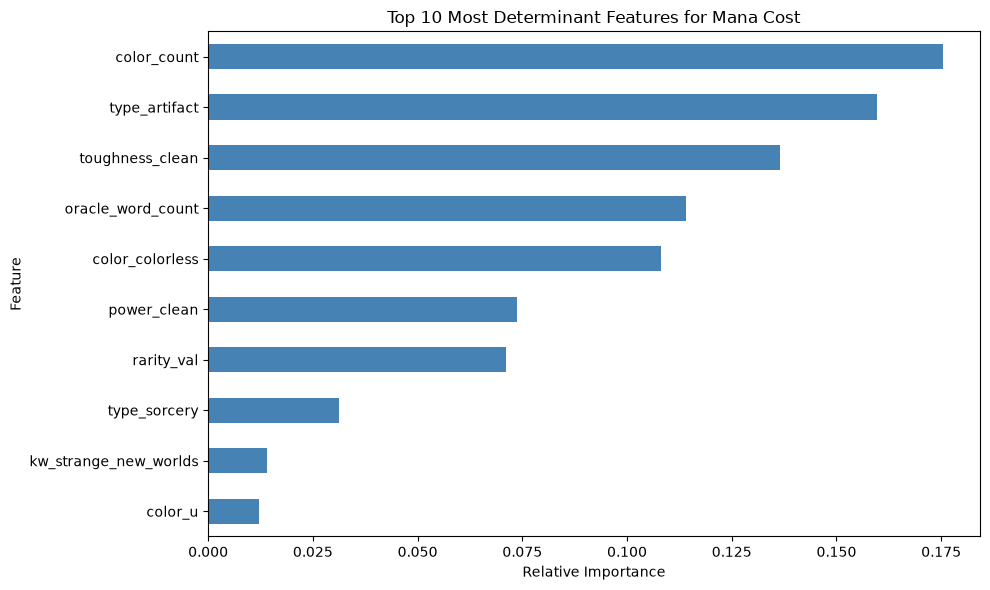

In [13]:
import matplotlib.pyplot as plt
import pandas as pd

# --- 1. Residual Analysis ---
# Reconstruct a dataframe to compare actuals vs predictions
results = pd.DataFrame({
    'Card Name': df_unique.loc[X_test.index, 'name'],
    'Actual CMC': y_test,
    'Predicted CMC': y_pred.round(2)
})

# Calculate absolute error
results['Error'] = abs(results['Actual CMC'] - results['Predicted CMC'])

print("--- Top 5 Largest Prediction Errors ---")
display(results.sort_values(by='Error', ascending=False).head(10))
print("\n")

# --- 2. Feature Importance Bar Chart ---
# Extract importances and map them to the column names
importances = pd.Series(rf_model.feature_importances_, index=X_train.columns)

# Isolate the top 10 most impactful features, sorted for a horizontal plot
top_features = importances.sort_values(ascending=True).tail(10)

# Generate the bar graph
plt.figure(figsize=(10, 6))
top_features.plot(kind='barh', color='steelblue')
plt.title('Top 10 Most Determinant Features for Mana Cost')
plt.xlabel('Relative Importance')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()

## 13. Accuracy, Precision, Recall, F1-Scores
Calculate classification metrics (Accuracy, Precision, Recall, F1-Scores) to measure the exact match rate. Evaluating the model using Accuracy, Precision, Recall, and F1-Scores to track the exact match rate, whereas the notebook currently only calculates the regression metrics (MAE and MSE).

In [17]:
from sklearn.metrics import f1_score, precision_score, recall_score, accuracy_score

# Round continuous predictions to the nearest whole number to simulate exact mana costs
y_pred_rounded = np.round(y_pred)

ac_test = accuracy_score(y_test, y_pred_rounded)
print("The accuracy score is {:.3f}".format(ac_test))

# Use average='weighted' for multi-class metrics instead of a binary pos_label
pc_test = precision_score(y_test, y_pred_rounded, average='weighted', zero_division=0)
print("The precision score is {:.3f}".format(pc_test))

rc_test = recall_score(y_test, y_pred_rounded, average='weighted', zero_division=0)
print("The recall score is {:.3f}".format(rc_test))

f1_test = f1_score(y_test, y_pred_rounded, average='weighted', zero_division=0)
print("The F1 score is {:.3f}".format(f1_test))



The accuracy score is 0.515
The precision score is 0.524
The recall score is 0.515
The F1 score is 0.512


## 14. Export to CSV for Tableau Dashboard

In [18]:
# 1. Prepare the Predictions Data
# Combine the test set features, actual CMC, and predictions into one DataFrame
export_df = X_test.copy()

# Bring in the Card Names from the unique dataframe using the index
export_df['Card Name'] = df_unique.loc[X_test.index, 'name']
export_df['Actual CMC'] = y_test
export_df['Predicted CMC'] = y_pred.round(2)
export_df['Prediction Error'] = abs(export_df['Actual CMC'] - export_df['Predicted CMC'])

# Reorder columns to put the most important identifying info first
cols = ['Card Name', 'Actual CMC', 'Predicted CMC', 'Prediction Error'] + \
       [col for col in export_df.columns if col not in ['Card Name', 'Actual CMC', 'Predicted CMC', 'Prediction Error']]
export_df = export_df[cols]

# Export to CSV
export_df.to_csv("mtg_mana_predictions.csv", index=False)
print("Saved 'mtg_mana_predictions.csv'")


# 2. Prepare the Feature Importances Data
importances_df = pd.DataFrame({
    'Feature': X_train.columns,
    'Importance': rf_model.feature_importances_
}).sort_values(by='Importance', ascending=False)

# Export to CSV
importances_df.to_csv("mtg_feature_importances.csv", index=False)
print("Saved 'mtg_feature_importances.csv'")

Saved 'mtg_mana_predictions.csv'
Saved 'mtg_feature_importances.csv'
